# Experiment 3: Processing Data

**Name:** Rudra Gupta  
**SAP ID:** 500120437

**Aim:**
1. Read a text document and perform basic pre-processing: tokenization, stop-word removal, lemmatization etc.
2. Study and implementation of morphological analysis.

**Input file:** `sample_text.txt` (kept in this folder).

## Step 1: Install and import the required packages

In [1]:
%pip install nltk spacy pandas matplotlib --quiet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import string
import pandas as pd
import nltk
import spacy

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

### Chart style

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
BLUE, BLUE_LIGHT, MUTED = "#2a78d6", "#9ec5f4", "#8a8984"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 11, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 28,
    "figure.dpi": 110,
})


def titles(ax, title, subtitle=None):
    ax.set_title(title, color=INK)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 7),
                    textcoords="offset points", color=INK2, fontsize=10.5, va="bottom")


def hbar(ax, labels, values, color=BLUE, fmt="{:,.0f}", highlight=None, highlight_color=BLUE):
    """Horizontal bars, largest at the top, with the value printed at the end of each bar."""
    labels, values = list(labels)[::-1], list(values)[::-1]
    colors = [highlight_color if l == highlight else color for l in labels]
    bars = ax.barh(labels, values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=2)
    vmax = max(values)
    for b, v in zip(bars, values):
        ax.text(b.get_width() + vmax * 0.012, b.get_y() + b.get_height() / 2, fmt.format(v),
                va="center", fontsize=10, color=INK, zorder=4,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
    ax.set_xlim(0, vmax * 1.14)
    ax.xaxis.set_visible(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=10.5, labelcolor=INK)

# Part 1: Text pre-processing

## 1.1 Read the text document

In [4]:
with open("sample_text.txt", encoding="utf-8") as f:
    raw_text = f.read()

print(f"Characters: {len(raw_text):,}")
print(raw_text[:500], "...")

Characters: 3,048
The Evolution of Natural Language Processing

Natural Language Processing (NLP) is a branch of Artificial Intelligence that teaches computers to read, understand and generate human language. In the 1950s, researchers believed that translating Russian into English would be solved within a few years. That prediction was carelessly optimistic, and the early systems misunderstood even simple sentences. The disappointment led to a long period of reduced funding, often called the "AI winter".

During  ...


## 1.2 Sentence tokenization
Done on the raw text, before cleaning removes the full stops. Each paragraph is split separately so the title stays on its own.

In [5]:
from nltk.tokenize import sent_tokenize, word_tokenize

paragraphs = [p for p in raw_text.split("\n\n") if p.strip()]
sentences = [s for p in paragraphs for s in sent_tokenize(" ".join(p.split()))]
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences[:5], 1):
    print(f"{i}. {s}")

Number of sentences: 31
1. The Evolution of Natural Language Processing
2. Natural Language Processing (NLP) is a branch of Artificial Intelligence that teaches computers to read, understand and generate human language.
3. In the 1950s, researchers believed that translating Russian into English would be solved within a few years.
4. That prediction was carelessly optimistic, and the early systems misunderstood even simple sentences.
5. The disappointment led to a long period of reduced funding, often called the "AI winter".


## 1.3 Lowercasing and cleaning
Remove URLs, email addresses, numbers and punctuation.

In [6]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.replace("-", " ")
    text = text.translate(str.maketrans("", "", string.punctuation))
    return re.sub(r"\s+", " ", text).strip()

cleaned_text = clean_text(raw_text)
print("Before:", sentences[-1])
print("After :", clean_text(sentences[-1]))

Before: For more information, visit https://www.example.org/nlp-history or write to info@example.org.
After : for more information visit or write to


## 1.4 Word tokenization

In [7]:
tokens = word_tokenize(cleaned_text)
print("Number of tokens:", len(tokens))
print(tokens[:30])

Number of tokens: 451
['the', 'evolution', 'of', 'natural', 'language', 'processing', 'natural', 'language', 'processing', 'nlp', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence', 'that', 'teaches', 'computers', 'to', 'read', 'understand', 'and', 'generate', 'human', 'language', 'in', 'the', 's', 'researchers']


## 1.5 Stop-word removal
Stop words (*the, is, and, of ...*) are very common and carry little meaning.

In [8]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))
filtered = [t for t in tokens if t not in stop_words and len(t) > 1]

print(f"Before: {len(tokens)} tokens   After: {len(filtered)} tokens   Removed: {len(tokens) - len(filtered)}")
print(filtered[:30])

Before: 451 tokens   After: 286 tokens   Removed: 165
['evolution', 'natural', 'language', 'processing', 'natural', 'language', 'processing', 'nlp', 'branch', 'artificial', 'intelligence', 'teaches', 'computers', 'read', 'understand', 'generate', 'human', 'language', 'researchers', 'believed', 'translating', 'russian', 'english', 'would', 'solved', 'within', 'years', 'prediction', 'carelessly', 'optimistic']


## 1.6 Stemming
A stemmer cuts word endings by rule; the result may not be a real word.

In [9]:
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer

porter, snowball, lancaster = PorterStemmer(), SnowballStemmer("english"), LancasterStemmer()
demo_words = ["running", "ran", "studies", "studying", "happiness", "better", "geese", "organization", "caring"]

pd.DataFrame({"Word": demo_words,
              "Porter": [porter.stem(w) for w in demo_words],
              "Snowball": [snowball.stem(w) for w in demo_words],
              "Lancaster": [lancaster.stem(w) for w in demo_words]})

,Word,Porter,Snowball,Lancaster
0,running,run,run,run
1,ran,ran,ran,ran
2,studies,studi,studi,study
3,studying,studi,studi,study
4,happiness,happi,happi,happy
5,better,better,better,bet
6,geese,gees,gees,gees
7,organization,organ,organ,org
8,caring,care,care,car


## 1.7 Lemmatization
A lemmatizer uses a dictionary (WordNet) to return the real base form. It needs the part of speech: without it every word is treated as a noun.

In [10]:
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

wnl = WordNetLemmatizer()

def wordnet_pos(tag):
    return {"J": "a", "V": "v", "N": "n", "R": "r"}.get(tag[0], "n")

# correct POS for the demo words (single words have no context for pos_tag)
demo_pos = {"running": "v", "ran": "v", "studies": "v", "studying": "v", "happiness": "n",
            "better": "a", "geese": "n", "organization": "n", "caring": "v"}

pd.DataFrame({"Word": demo_words,
              "Lemma (no POS)": [wnl.lemmatize(w) for w in demo_words],
              "Lemma (with POS)": [wnl.lemmatize(w, demo_pos[w]) for w in demo_words],
              "Porter stem": [porter.stem(w) for w in demo_words]})

,Word,Lemma (no POS),Lemma (with POS),Porter stem
0,running,running,run,run
1,ran,ran,run,ran
2,studies,study,study,studi
3,studying,studying,study,studi
4,happiness,happiness,happiness,happi
5,better,better,good,better
6,geese,goose,goose,gees
7,organization,organization,organization,organ
8,caring,caring,care,care


Lemmatization returns real words and handles irregular forms (*ran -> run*, *geese -> goose*, *better -> good*); stemming does not.

## 1.8 The complete pre-processing pipeline

In [11]:
lemmas = [wnl.lemmatize(w, wordnet_pos(t)) for w, t in pos_tag(filtered)]

with open("processed_text.txt", "w", encoding="utf-8") as f:
    f.write(" ".join(lemmas))

print(f"{len(lemmas)} tokens, {len(set(lemmas))} unique - saved to 'processed_text.txt'")
print(lemmas[:40])

286 tokens, 224 unique - saved to 'processed_text.txt'
['evolution', 'natural', 'language', 'process', 'natural', 'language', 'processing', 'nlp', 'branch', 'artificial', 'intelligence', 'teach', 'computer', 'read', 'understand', 'generate', 'human', 'language', 'researcher', 'believe', 'translate', 'russian', 'english', 'would', 'solve', 'within', 'year', 'prediction', 'carelessly', 'optimistic', 'early', 'system', 'misunderstand', 'even', 'simple', 'sentence', 'disappointment', 'lead', 'long', 'period']


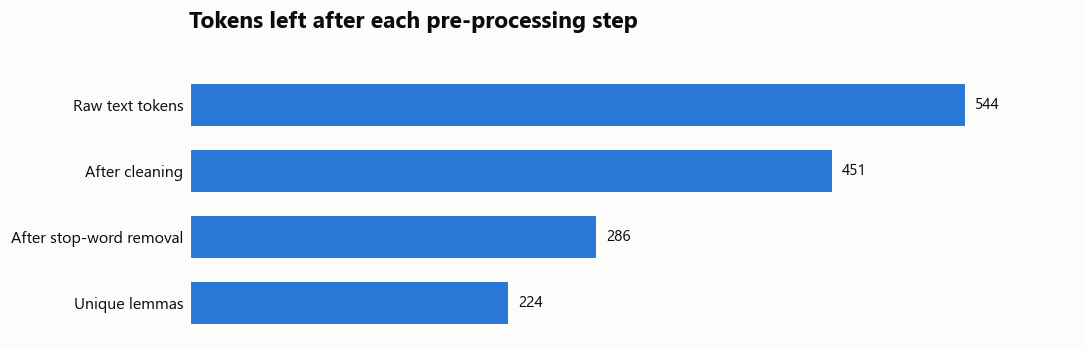

In [12]:
stages = pd.Series({"Raw text tokens": len(word_tokenize(raw_text)), "After cleaning": len(tokens),
                    "After stop-word removal": len(filtered), "Unique lemmas": len(set(lemmas))})
fig, ax = plt.subplots(figsize=(10, 3.3))
hbar(ax, stages.index, stages.values)
titles(ax, "Tokens left after each pre-processing step")
plt.tight_layout()
plt.show()

# Part 2: Morphological analysis

**Morphology** studies how words are built from **morphemes**, the smallest units of meaning.
- **Free morphemes** stand alone (*happy, teach*); **bound morphemes** attach to others (*un-, -ness, -s*).
- **Inflectional** morphemes change grammatical form without creating a new word: plural *-s*, past *-ed*, *-ing*, comparative *-er*, superlative *-est*.
- **Derivational** morphemes create a new word, often of a new class: *happy -> unhappiness*, *agree -> disagreement*.

Example: *unbelievable* = **un-** (prefix) + **believe** (root) + **-able** (derivational suffix).

## 2.1 Inflectional analysis
spaCy gives each word its lemma and morphological features (e.g. `Number=Plur`, `Tense=Past`). An inflection is **irregular** when it doesn't add the usual ending (*child -> children*).

In [13]:
ENDINGS = {"plural": ("s",), "past": ("ed", "d"), "-ing": ("ing",), "3rd person singular": ("s",),
           "comparative": ("er",), "superlative": ("est",)}

def inflection(tok):
    m = tok.morph.to_dict()
    if tok.pos_ in ("NOUN", "PROPN") and m.get("Number") == "Plur": kind = "plural"
    elif m.get("Aspect") == "Prog": kind = "-ing"
    elif m.get("Tense") == "Past": kind = "past"
    elif m.get("Person") == "3" and m.get("Tense") == "Pres" and tok.pos_ in ("VERB", "AUX"): kind = "3rd person singular"
    elif m.get("Degree") == "Cmp": kind = "comparative"
    elif m.get("Degree") == "Sup": kind = "superlative"
    else:
        return None
    w, lem = tok.text.lower(), tok.lemma_.lower()
    if w == lem:
        return None
    regular = w.endswith(ENDINGS[kind]) and w.startswith(lem[: max(1, len(lem) - 1)])
    return kind, "regular" if regular else "irregular"

doc = nlp(" ".join(raw_text.split()))
rows = [{"Word": t.text, "Lemma": t.lemma_, "POS": t.pos_, "Features": str(t.morph),
         "Inflection": inf[0], "Type": inf[1]}
        for t in doc if t.is_alpha and (inf := inflection(t))]
infl_df = pd.DataFrame(rows).drop_duplicates("Word")
print(f"{len(infl_df)} distinct inflected words; {(infl_df['Type'] == 'irregular').sum()} irregular")
infl_df.sort_values(["Type", "Inflection"]).head(20)

92 distinct inflected words; 12 irregular


,Word,Lemma,POS,Features,Inflection,Type
0,is,be,AUX,Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbF...,3rd person singular,irregular
108,has,have,AUX,Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbF...,3rd person singular,irregular
30,better,well,ADJ,Degree=Cmp,comparative,irregular
8,was,be,AUX,Mood=Ind|Number=Sing|Person=3|Tense=Past|VerbF...,past,irregular
11,led,lead,VERB,Tense=Past|VerbForm=Fin,past,irregular
36,were,be,AUX,Mood=Ind|Tense=Past|VerbForm=Fin,past,irregular
85,ran,run,VERB,Tense=Past|VerbForm=Fin,past,irregular
96,found,find,VERB,Aspect=Perf|Tense=Past|VerbForm=Part,past,irregular
109,been,be,AUX,Tense=Past|VerbForm=Part,past,irregular
71,children,child,NOUN,Number=Plur,plural,irregular


## 2.2 Derivational analysis: splitting words into morphemes
A rule-based analyzer that splits a word into **prefix + root + suffix**:
1. Start from the lemma (inflections are already removed).
2. Strip a known suffix if what's left is a real WordNet word of the right class (*-ness* attaches to adjectives, *-ment* to verbs), undoing spelling changes (*happi -> happy*, *believ -> believe*).
3. Except for very regular suffixes (*-ness, -less, -ful, -ly, -ment*), WordNet must also link the two words, which stops false splits like *billion -> bill + -ion*.
4. Otherwise strip a known prefix if the root is a real word (linked in WordNet or at least 5 letters long).
5. Repeat until nothing more can be removed.

In [14]:
from nltk.corpus import wordnet as wn

WN_POS = {"n": {"n"}, "v": {"v"}, "a": {"a", "s"}}
PREFIXES = {"inter": "nav", "trans": "nav", "multi": "na", "non": "na", "mis": "v", "dis": "va",
            "pre": "vn", "un": "av", "re": "v", "im": "a", "in": "a", "ir": "a", "il": "a"}
SUFFIXES = {"ization": "na", "ation": "v", "ion": "v", "ment": "v", "ness": "a", "ity": "a", "er": "v",
            "or": "v", "ist": "na", "ism": "na", "able": "v", "ible": "v", "ful": "n", "less": "n",
            "ous": "n", "ive": "v", "al": "n", "ic": "n", "ize": "na", "ise": "na", "ify": "na", "ly": "a"}
TRANSPARENT = {"ness", "less", "ful", "ly", "ment"}

def is_word(word, poses="nva"):
    ok = set().union(*(WN_POS[p] for p in poses))
    return any(s.pos() in ok and any(l.name().lower() == word for l in s.lemmas()) for s in wn.synsets(word))

def links(word):
    out = set()
    for syn in wn.synsets(word):
        for lem in syn.lemmas():
            if lem.name().lower() == word:
                out |= {r.name().lower() for r in lem.derivationally_related_forms() + lem.antonyms() + lem.pertainyms()}
    return out

def related(word, root):
    a, b = links(word), links(root)
    return root in a or word in b or (len(root) >= 4 and bool(a & b))

def stem_candidates(s):
    c = [s, s + "e"]
    if s.endswith("i"):  c.append(s[:-1] + "y")
    if s.endswith("il"): c.append(s[:-2] + "le")
    if len(s) > 2 and s[-1] == s[-2]: c.append(s[:-1])
    return [x for x in c if len(x) >= 3]

def segment(word):
    prefixes, suffixes, root = [], [], word.lower()
    changed = True
    while changed:
        changed = False
        for suf in sorted(SUFFIXES, key=len, reverse=True):
            if root.endswith(suf) and len(root) - len(suf) >= 3:
                for cand in stem_candidates(root[: -len(suf)]):
                    if is_word(cand, SUFFIXES[suf]) and (suf in TRANSPARENT or related(root, cand)):
                        suffixes.insert(0, suf); root = cand; changed = True
                        break
            if changed: break
        if changed: continue
        for pre in sorted(PREFIXES, key=len, reverse=True):
            rest = root[len(pre):]
            if (root.startswith(pre) and len(rest) >= 4 and is_word(rest, PREFIXES[pre])
                    and (related(root, rest) or len(rest) >= 5)):
                prefixes.append(pre); root = rest; changed = True
                break
    return prefixes, root, suffixes

def show(prefixes, root, suffixes):
    return " + ".join([p + "-" for p in prefixes] + [root.upper()] + ["-" + s for s in suffixes])

for w in ["unhappiness", "unbelievable", "disagreement", "carelessly", "computational",
          "meaningful", "impossible", "unfairness", "manageable", "teacher"]:
    print(f"{w:<15} ->  {show(*segment(w))}")

unhappiness     ->  un- + HAPPY + -ness
unbelievable    ->  un- + BELIEVE + -able
disagreement    ->  dis- + AGREE + -ment
carelessly      ->  CARE + -less + -ly
computational   ->  COMPUTE + -ation + -al
meaningful      ->  MEANING + -ful
impossible      ->  im- + POSSIBLE
unfairness      ->  un- + FAIR + -ness
manageable      ->  MANAGE + -able
teacher         ->  TEACH + -er


## 2.3 Morphological analysis of the document
Inflection (from spaCy) and derivation (from our analyzer) for every content word with more than one morpheme.

In [15]:
INFL_SUFFIX = {"plural": "-s", "past": "-ed", "-ing": "-ing", "3rd person singular": "-s",
               "comparative": "-er", "superlative": "-est"}
rows = []
for t in doc:
    if t.is_alpha and t.pos_ in ("NOUN", "VERB", "ADJ", "ADV") and t.text.lower() not in stop_words:
        p, r, s = segment(t.lemma_.lower())
        inf = inflection(t)
        infl = (INFL_SUFFIX[inf[0]] if inf[1] == "regular" else f"irregular {inf[0]}") if inf else ""
        if p or s or inf:
            rows.append({"Word": t.text.lower(), "Lemma": t.lemma_.lower(), "Prefix": " ".join(x + "-" for x in p),
                         "Root": r, "Derivational suffix": " ".join("-" + x for x in s), "Inflection": infl})
morph_df = pd.DataFrame(rows).drop_duplicates("Word")
print(f"{len(morph_df)} words with more than one morpheme")
morph_df[(morph_df["Prefix"] != "") | (morph_df["Derivational suffix"] != "")].reset_index(drop=True)

111 words with more than one morpheme


,Word,Lemma,Prefix,Root,Derivational suffix,Inflection
0,computers,computer,,compute,-er,-s
1,researchers,researcher,re-,search,-er,-s
2,prediction,prediction,,predict,-ion,
3,carelessly,carelessly,,care,-less -ly,
4,optimistic,optimistic,,optimist,-ic,
5,disappointment,disappointment,dis-,appoint,-ment,
6,rethinking,rethink,re-,think,,-ing
7,collections,collection,,collect,-ion,-s
8,probabilities,probability,,probable,-ity,-s
9,computational,computational,,compute,-ation -al,


**Limitation:** the rules only check that the pieces are real words, so a few words are over-split (*represent -> re- + present*, *discover -> dis- + cover*) and some real affixes are missed when WordNet doesn't link the words (*reliable* is not split into *rely + -able*). Real systems use large morpheme dictionaries or statistical models such as Morfessor.

## Conclusion
**Part 1:** We read `sample_text.txt`, split it into sentences and words, cleaned it, removed stop words, compared three stemmers with WordNet lemmatization (which returns real dictionary words and handles irregular forms), and saved the processed tokens to `processed_text.txt`.

**Part 2:** We used spaCy's morphological features to find inflections and separate regular from irregular forms, and implemented a rule-based analyzer that splits words into prefix + root + suffix (e.g. *un- + HAPPY + -ness*), applying both to the document.